# COVID-19 in Armenia: Data Quality, Trends and a Forecasting Experiment

**Portfolio revision of a university group project | Vane Sargsyan**

This notebook reviews 134 reported observations from 3 February to 26 June 2020. Its main focus is data validation, exploratory analysis, clear reporting and honest evaluation. The forecasting section is a small educational experiment, not a public-health forecasting service.

## Attribution and scope

The original presentation attributes **trend analysis, visualizations and model evaluation** to Vane. Mariam contributed preprocessing and feature engineering; Knarik contributed exploratory analysis and prediction generation; Elen contributed model implementation, visualization and model comparison. This revised notebook does not claim that the original team work was completed by Vane alone.

The submitted notebook contains a Random Forest experiment, while the presentation compares other models. This edition uses the supplied notebook as its base, adds explicit baselines, and recomputes all results. The old slide metrics are not reused.

## Run

Install `requirements.txt`, open this notebook from the extracted project folder and select **Restart Kernel and Run All Cells**. In Colab, upload both this notebook and `Armenian_COVID_Data.csv` to the session, then run all cells. No signed download links or credentials are required.

## 1. Source and data definitions

Source credited in the coursework: [Natalya Bakhshetyan, COVID-19 in Armenia, Kaggle](https://www.kaggle.com/datasets/natalyabakhshetyan/covid19-in-armenia). The input is the CSV supplied with the coursework; its bytes are preserved in `data/`.

| Column | Working interpretation |
|---|---|
| date | Reporting date, day.month.year |
| confirmed_cases | Reported confirmed cases on that date |
| recovered | Reported recoveries on that date |
| negative_tests | Reported negative tests on that date |
| deaths | Reported deaths on that date |

**Interpretation caveat:** the non-monotonic counts are consistent with daily reports, not cumulative totals. This revision treats them as reported daily counts without applying `.diff()`. The uploaded CSV has no data dictionary; confirm the upstream definitions before operational use. Missing reporting dates are unknown, not zero. The license is not included in the supplied CSV; verify the upstream redistribution terms before publishing the dataset publicly.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

candidates = [Path('data/Armenian_COVID_Data.csv'), Path('Armenian_COVID_Data.csv')]
DATA_PATH = next((path for path in candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Upload Armenian_COVID_Data.csv or run from the extracted project folder.')
REPORTS = Path('reports')
FIGURES = REPORTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
raw = pd.read_csv(DATA_PATH)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')
print(f'Input: {len(raw)} rows, {len(raw.columns)} columns')
display(raw.head())

Python 3.12.14 | pandas 2.2.3 | scikit-learn 1.8.0
Input: 134 rows, 5 columns


,date,confirmed_cases,recovered,negative_tests,deaths
0,03.02.2020,0,0,6,0
1,04.02.2020,0,0,12,0
2,05.02.2020,0,0,5,0
3,06.02.2020,0,0,16,0
4,07.02.2020,0,0,9,0


## 2. Data quality checks

Dates are parsed explicitly, counts are checked for numeric values, and invalid or negative counts stop execution. Exact duplicate rows would be removed and reported. Duplicate dates stop execution rather than silently summing potentially duplicated reports. Missing dates are recorded separately.

In [2]:
count_cols = ['confirmed_cases', 'recovered', 'negative_tests', 'deaths']
expected = ['date'] + count_cols
if set(raw.columns) != set(expected):
    raise ValueError(f'Unexpected columns: {list(raw.columns)}')
df = raw.copy()
df['date'] = pd.to_datetime(df['date'], format='%d.%m.%Y', errors='raise')
for col in count_cols:
    df[col] = pd.to_numeric(df[col], errors='raise')
if df[expected].isna().any().any():
    raise ValueError('Missing values require investigation before analysis.')
values = df[count_cols].to_numpy(dtype=float)
if not np.isfinite(values).all() or (values < 0).any() or (values != np.floor(values)).any():
    raise ValueError('Counts must be finite, non-negative integers.')
exact_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().sort_values('date').reset_index(drop=True)
if df['date'].duplicated().any():
    raise ValueError('Conflicting reports share a date; resolve against the source.')
calendar = pd.date_range(df['date'].min(), df['date'].max(), freq='D')
missing_dates = calendar.difference(pd.DatetimeIndex(df['date']))
quality = pd.DataFrame({
    'check': ['input rows', 'exact duplicates removed', 'missing cells', 'duplicate dates', 'missing calendar dates'],
    'value': [len(raw), exact_duplicates, int(df.isna().sum().sum()), int(df.date.duplicated().sum()), len(missing_dates)]
})
display(quality)
print('Coverage:', df.date.min().date(), 'to', df.date.max().date())
print('Unreported dates:', ', '.join(missing_dates.strftime('%Y-%m-%d')))
print('Day-to-day decreases, supporting the daily-count interpretation:')
display(df[count_cols].diff().lt(0).sum().rename('decreases').to_frame())
quality.to_csv(REPORTS / 'data_quality.csv', index=False)
df.to_csv(REPORTS / 'validated_observations.csv', index=False)

,check,value
0,input rows,134
1,exact duplicates removed,0
2,missing cells,0
3,duplicate dates,0
4,missing calendar dates,11


Coverage: 2020-02-03 to 2020-06-26
Unreported dates: 2020-02-08, 2020-02-09, 2020-02-12, 2020-02-13, 2020-02-15, 2020-02-16, 2020-02-17, 2020-02-20, 2020-02-21, 2020-02-22, 2020-02-23
Day-to-day decreases, supporting the daily-count interpretation:


,decreases
confirmed_cases,45
recovered,47
negative_tests,63
deaths,32


## 3. Exploratory analysis in original units

The charts use reported counts, not standardized values. Calendar gaps remain missing. A seven-day average is displayed only when all seven days are observed; gaps are not interpolated. Correlation is descriptive association and does not establish causation or a biological delay between infection and death.

,confirmed_cases,recovered,negative_tests,deaths
count,134.00,134.00,134.00,134.00
mean,178.43,96.35,620.89,3.13
std,221.90,191.24,531.93,4.60
min,0.00,0.00,0.00,0.00
25%,16.25,0.00,73.75,0.00
50%,62.00,25.00,634.00,1.00
75%,321.50,74.25,982.75,4.00
max,771.00,1013.00,1731.00,19.00


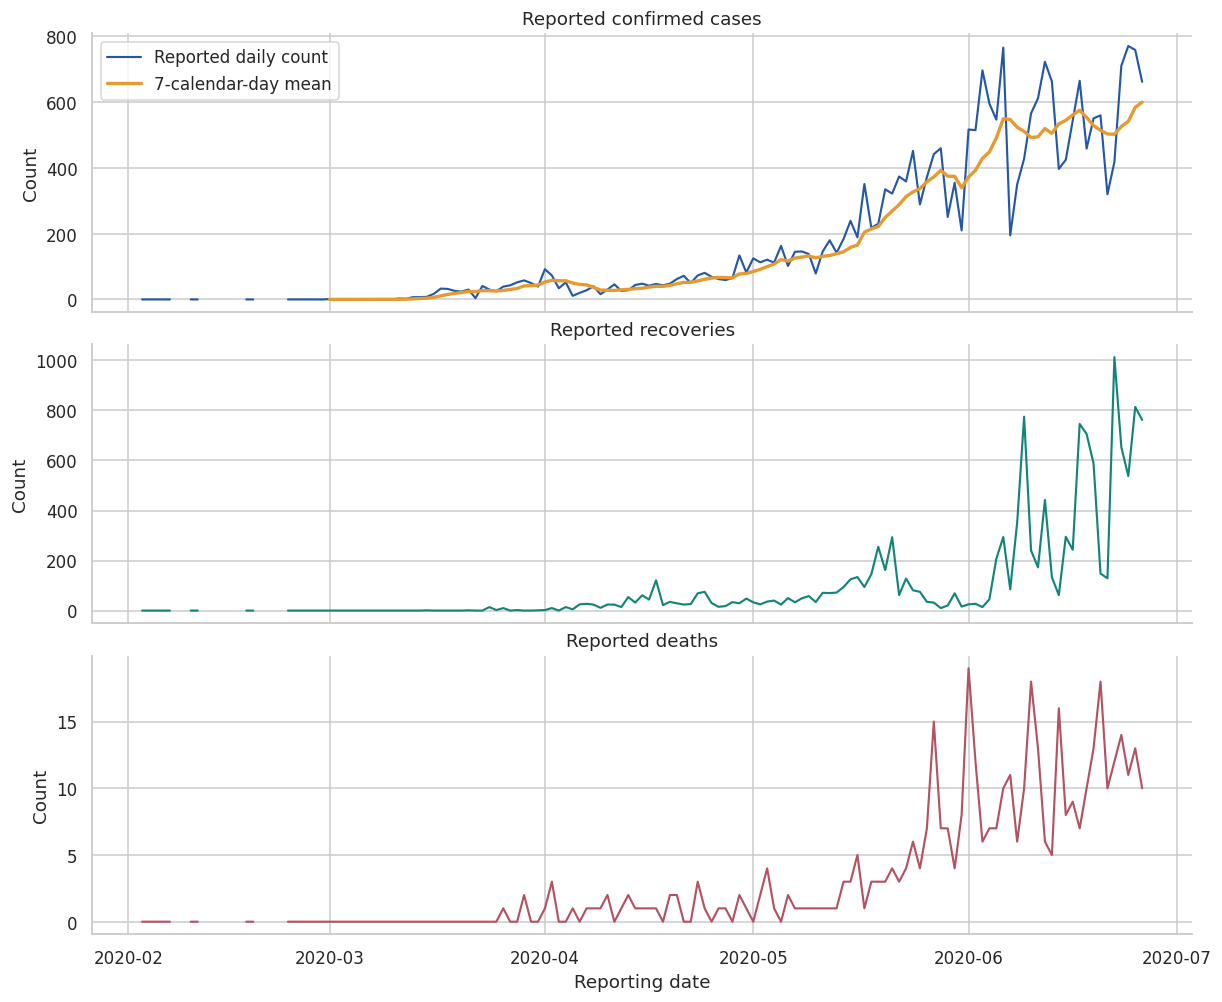

In [3]:
display(df[count_cols].describe().round(2))
daily = df.set_index('date').reindex(calendar)
daily.index.name = 'date'
rolling = daily['confirmed_cases'].rolling(7, min_periods=7).mean()
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, constrained_layout=True)
for ax, col, title, color in zip(axes, ['confirmed_cases', 'recovered', 'deaths'], ['Reported confirmed cases', 'Reported recoveries', 'Reported deaths'], ['#2458a6', '#138577', '#b35262']):
    ax.plot(daily.index, daily[col], color=color, linewidth=1.4, label='Reported daily count')
    ax.set(title=title, ylabel='Count')
axes[0].plot(rolling.index, rolling, color='#e69b32', linewidth=2.2, label='7-calendar-day mean')
axes[0].legend(loc='upper left')
axes[-1].set_xlabel('Reporting date')
fig.savefig(FIGURES / 'reported_trends.png', dpi=160)
plt.show()

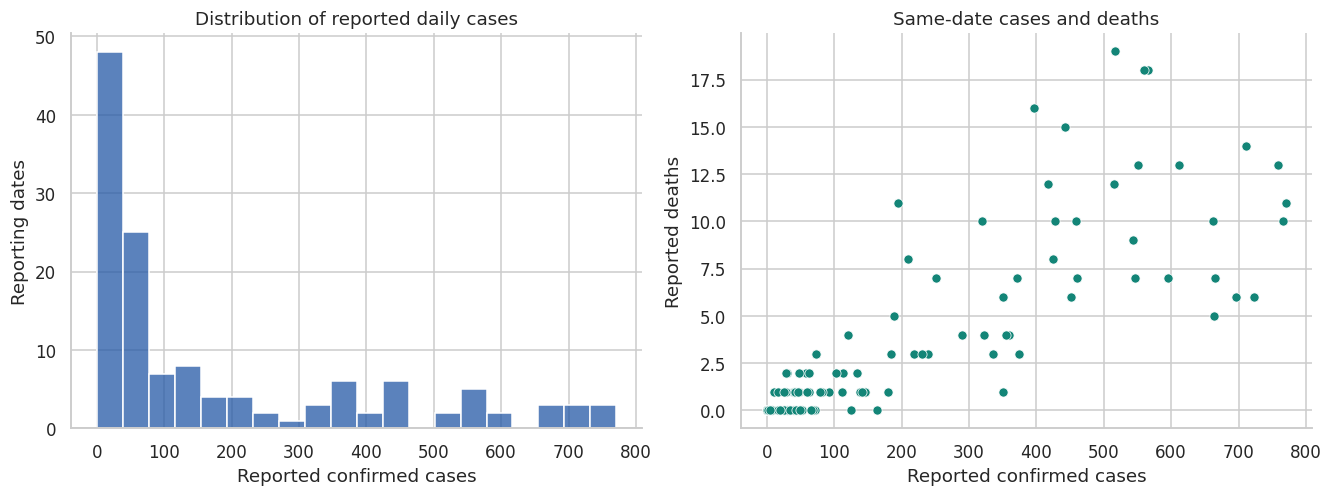

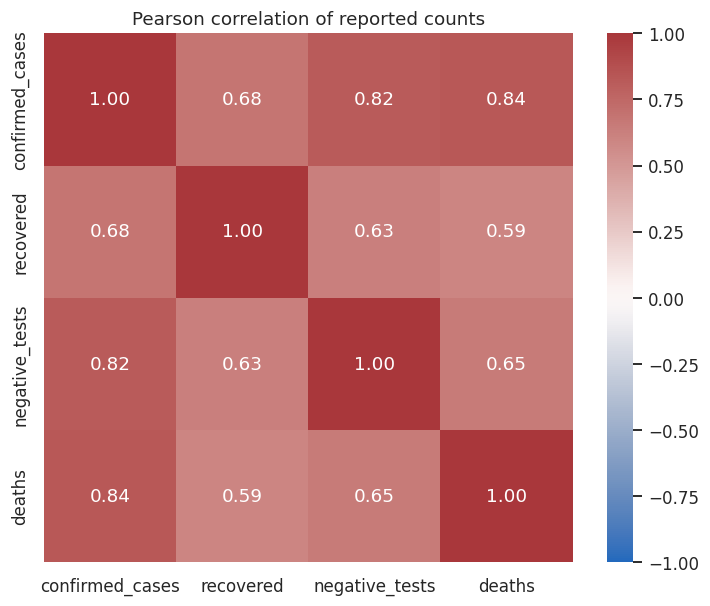

Largest reported daily confirmed count: 771 on 2020-06-24.
Same-date confirmed/deaths Pearson r: 0.835.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
sns.histplot(data=df, x='confirmed_cases', bins=20, color='#2458a6', ax=axes[0])
axes[0].set(title='Distribution of reported daily cases', xlabel='Reported confirmed cases', ylabel='Reporting dates')
sns.scatterplot(data=df, x='confirmed_cases', y='deaths', color='#138577', ax=axes[1])
axes[1].set(title='Same-date cases and deaths', xlabel='Reported confirmed cases', ylabel='Reported deaths')
fig.savefig(FIGURES / 'distribution_and_scatter.png', dpi=160)
plt.show()
correlation = df[count_cols].corr()
fig, ax = plt.subplots(figsize=(7.5, 5.4), constrained_layout=True)
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Pearson correlation of reported counts')
fig.savefig(FIGURES / 'correlation_heatmap.png', dpi=160)
plt.show()
correlation.to_csv(REPORTS / 'correlations.csv')
peak = df.loc[df.confirmed_cases.idxmax()]
print(f'Largest reported daily confirmed count: {int(peak.confirmed_cases)} on {peak.date:%Y-%m-%d}.')
print(f'Same-date confirmed/deaths Pearson r: {correlation.loc["confirmed_cases", "deaths"]:.3f}.')

## 4. Define an explicit forecasting experiment

At the end of reporting day **t**, use observations available through **t** to estimate confirmed cases on calendar day **t+1**. This assumes that the current day's reports are available at forecast time. It is a sequence of one-step predictions, not a multi-day forecast made at the start of the test period.

The target is tomorrow's reported `confirmed_cases` in original count units. Today’s count is a valid predictor under this forecast-time assumption. Past values use calendar-day shifts. Missing dates remain NaN; rows lacking features or the next day's target are excluded explicitly, never filled with zeros. The target is created once.

In [5]:
features = daily[count_cols].copy()
for lag in [1, 2, 3, 7]:
    features[f'confirmed_lag_{lag}'] = daily['confirmed_cases'].shift(lag)
features['confirmed_7day_mean'] = daily['confirmed_cases'].rolling(7, min_periods=7).mean()
features['confirmed_7day_std'] = daily['confirmed_cases'].rolling(7, min_periods=7).std()
table = features.copy()
table['target_date'] = table.index + pd.Timedelta(days=1)
table['target_next_day'] = daily['confirmed_cases'].shift(-1)
model_data = table.dropna().copy()
feature_cols = list(features.columns)
if not np.isfinite(model_data[feature_cols + ['target_next_day']].to_numpy()).all():
    raise ValueError('Non-finite modeling values remain.')
X = model_data[feature_cols]
y = model_data['target_next_day']
split = int(len(model_data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
if len(X_train) < 20 or len(X_test) < 2:
    raise ValueError('Too few observations for this educational split.')
if not (X_train.index.to_series().diff().dropna() == pd.Timedelta(days=1)).all():
    raise ValueError('Training rows are not equally spaced; revisit cross-validation.')
print(f'Calendar rows: {len(table)}; usable supervised rows: {len(model_data)}; excluded: {len(table) - len(model_data)}')
print(f'Train: {len(X_train)} rows; test: {len(X_test)} rows')
print(f'Train target dates: {model_data.target_date.iloc[0]:%Y-%m-%d} to {model_data.target_date.iloc[split-1]:%Y-%m-%d}')
print(f'Test target dates: {model_data.target_date.iloc[split]:%Y-%m-%d} to {model_data.target_date.iloc[-1]:%Y-%m-%d}')
display(model_data.head())

Calendar rows: 145; usable supervised rows: 116; excluded: 29
Train: 92 rows; test: 24 rows
Train target dates: 2020-03-03 to 2020-06-02
Test target dates: 2020-06-03 to 2020-06-26


,confirmed_cases,recovered,negative_tests,deaths,confirmed_lag_1,confirmed_lag_2,confirmed_lag_3,confirmed_lag_7,confirmed_7day_mean,confirmed_7day_std,target_date,target_next_day
date,,,,,,,,,,,,
2020-03-02,0.0,0.0,19.0,0.0,1.0,0.0,0.0,0.0,0.142857,0.377964,2020-03-03,0.0
2020-03-03,0.0,0.0,12.0,0.0,0.0,1.0,0.0,0.0,0.142857,0.377964,2020-03-04,0.0
2020-03-04,0.0,0.0,13.0,0.0,0.0,0.0,1.0,0.0,0.142857,0.377964,2020-03-05,0.0
2020-03-05,0.0,0.0,13.0,0.0,0.0,0.0,0.0,0.0,0.142857,0.377964,2020-03-06,0.0
2020-03-06,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,0.142857,0.377964,2020-03-07,0.0


## 5. Fit on training data; select using chronological validation

Baselines are persistence (tomorrow equals today), the training-target mean and Linear Regression. They are additions in this portfolio revision. Random Forest comes from the submitted notebook.

Random Forest settings are selected by the lowest mean cross-validation MAE within the training portion only. `TimeSeriesSplit` keeps validation after training; a one-row gap conservatively separates the shifted training labels from validation origins. Scaling for Linear Regression is inside a pipeline and is learned separately within each training fold. Neither the target nor the analysis dataframe is standardized. The final test period is not used for model selection.

In [6]:
cv = TimeSeriesSplit(n_splits=3, gap=1)
linear = make_pipeline(StandardScaler(), LinearRegression())
search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=1),
    {'n_estimators': [100], 'max_depth': [3, 5, None], 'min_samples_leaf': [2, 5]},
    cv=cv, scoring='neg_mean_absolute_error', n_jobs=1
)
search.fit(X_train, y_train)
rf = search.best_estimator_
fold_rows = []
for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), start=1):
    x_fit, x_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_fit, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    predictions = {
        'Persistence': x_val['confirmed_cases'].to_numpy(),
        'Training mean': np.full(len(x_val), y_fit.mean()),
        'Linear Regression': clone(linear).fit(x_fit, y_fit).predict(x_val),
        'Random Forest': clone(rf).fit(x_fit, y_fit).predict(x_val)
    }
    for name, pred in predictions.items():
        fold_rows.append({'model': name, 'fold': fold, 'MAE': mean_absolute_error(y_val, pred)})
fold_scores = pd.DataFrame(fold_rows)
cv_summary = fold_scores.groupby('model', sort=False)['MAE'].agg(['mean', 'std']).rename(columns={'mean': 'CV_MAE', 'std': 'fold_std'})
selected_name = cv_summary.CV_MAE.idxmin()
linear.fit(X_train, y_train)
print('Random Forest parameters selected within training:', search.best_params_)
display(cv_summary.round(2))
print('Model selected by training-only CV MAE:', selected_name)
cv_summary.to_csv(REPORTS / 'cross_validation.csv')

Random Forest parameters selected within training: {'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}


,CV_MAE,fold_std
model,,
Persistence,41.45,38.54
Training mean,119.22,124.48
Linear Regression,84.96,67.59
Random Forest,83.83,85.29


Model selected by training-only CV MAE: Persistence


## 6. Evaluate on the held-out final period

MAE and RMSE are in **reported cases**, so their scale is interpretable. R² can be negative: a negative value means the squared error exceeds that of a constant equal to the test-target mean. That diagnostic reference differs from the deployable training-mean baseline shown here.

Test errors are reported for transparency; the chosen model was already selected using training-only chronological validation. No result is described as reliable simply because it is the best in a small table.

,MAE,RMSE,R2
model,,,
Persistence,139.625,183.081,-0.440
Training mean,443.328,468.847,-8.443
Linear Regression,188.376,234.607,-1.365
Random Forest,183.825,211.906,-0.929


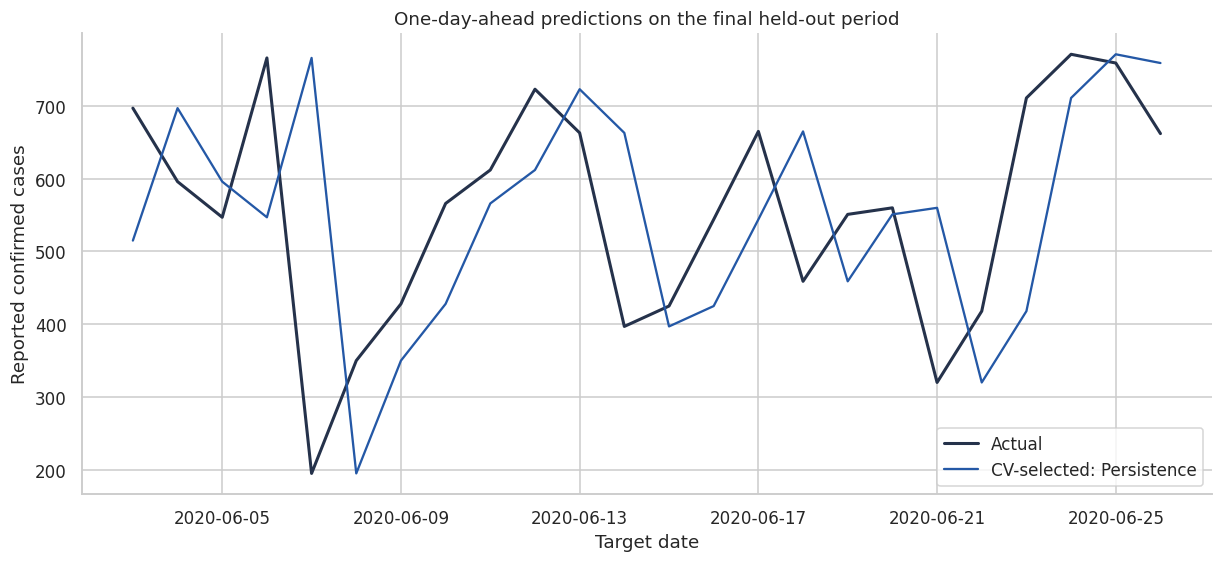

CV-selected Persistence: held-out MAE 139.62, RMSE 183.08, R2 -0.440.


In [7]:
test_predictions = {
    'Persistence': X_test['confirmed_cases'].to_numpy(),
    'Training mean': np.full(len(X_test), y_train.mean()),
    'Linear Regression': linear.predict(X_test),
    'Random Forest': rf.predict(X_test)
}
metrics = pd.DataFrame([
    {'model': name, 'MAE': mean_absolute_error(y_test, pred),
     'RMSE': np.sqrt(mean_squared_error(y_test, pred)), 'R2': r2_score(y_test, pred)}
    for name, pred in test_predictions.items()
]).set_index('model')
display(metrics.round(3))
metrics.to_csv(REPORTS / 'model_metrics.csv')
prediction_table = pd.DataFrame({'target_date': model_data.target_date.iloc[split:].to_numpy(), 'actual': y_test.to_numpy()})
for name, pred in test_predictions.items():
    prediction_table[name] = pred
prediction_table.to_csv(REPORTS / 'test_predictions.csv', index=False)
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
ax.plot(prediction_table.target_date, prediction_table.actual, color='#25324b', label='Actual', linewidth=2)
ax.plot(prediction_table.target_date, prediction_table[selected_name], color='#2458a6', label=f'CV-selected: {selected_name}')
if selected_name != 'Persistence':
    ax.plot(prediction_table.target_date, prediction_table['Persistence'], color='#e69b32', label='Persistence baseline', alpha=0.8)
ax.set(title='One-day-ahead predictions on the final held-out period', xlabel='Target date', ylabel='Reported confirmed cases')
ax.legend()
fig.savefig(FIGURES / 'held_out_predictions.png', dpi=160)
plt.show()
selected = metrics.loc[selected_name]
print(f'CV-selected {selected_name}: held-out MAE {selected.MAE:.2f}, RMSE {selected.RMSE:.2f}, R2 {selected.R2:.3f}.')

## 7. Interpretation and limitations

- The observed counts increase and fluctuate over the reporting period. Same-date associations do not prove causal relationships; reporting patterns and the shared trend may affect correlations.
- Only 134 original reports from a short early-pandemic period are available. Calendar gaps and lag requirements reduce the modeling sample further.
- Missing dates and the daily-versus-cumulative interpretation are explicit assumptions, not hidden corrections.
- This is a small historical holdout and three chronological validation folds. Differences between models do not establish robust generalization. The Random Forest validation estimate also participates in hyperparameter selection; it is not an independent performance estimate.
- The experiment assumes end-of-day access to all predictors. It does not model reporting delays, policy changes, testing capacity changes or causal effects.
- Feature engineering, the target, split and units differ from the submitted experiment. Revised numbers must not be compared directly with the old presentation.
- The next step is to verify source definitions and redistribution terms, gather a longer dataset, and evaluate rolling forecasts across several periods.

## 8. Portfolio revision record

Removed the expiring signed URL; loaded a local CSV; added data-contract and calendar checks; removed differencing of apparent daily counts; preserved original-unit charts; removed global scaling and repeated target construction; replaced ordinary CV with chronological CV; added baselines and reproducible exports; corrected unsupported statistical interpretations; and preserved team attribution.

References: [scikit-learn: common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html), [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).